In [2]:
import numpy as np
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.interpolate import interp1d
import plotly.graph_objects as go
from scipy.linalg import eigh, eig
import matplotlib.pyplot as plt
import pandas as pd
import time
from dataclasses import dataclass
import pickle
import inputs_metrotranvia
from inputs_metrotranvia import (
    L, sep_dur, n_tot, dof_malla, g,
    a_r, gamma_r, q0, m_r, e_r, nu, i_r, k_b, c_b,
    dano_nodal, gdl_restringidos,
    tren_params, cinematica_params, sim_params, carga_params,
    t_eval, t_sim
)

from utils.logger import log_inputs

log_file = log_inputs(inputs_metrotranvia)


Velocidad final de la carga: 15.0 m/s
Distancia recorrida en aceleración y crucero: 150.0 m
Posición final de la carga: 190.0 m
✔ Parámetros guardados en:
  datos_corrida\logs\run_2026-10-10_11-47-49.json
  datos_corrida\logs\run_2026-10-10_11-47-49.txt


In [3]:
class MallaRiel:
    def __init__(self, L, n_tot, dof, nodo_i=0):
        """
        Clase para generar la geometría de una viga.

        Args:
            L: (float) Longitud total de la viga [m].
            n_tot: (int) Cantidad total de nodos
            dof: (int) Grados de libertad por nodo.
            nodo_i: (float) Coordenada del nodo inicial (por defecto es 0.00)
        """
        self.L = L
        self.n_tot = n_tot
        self.dof = dof
        self.nodo_i = nodo_i
        self.coord_fin = nodo_i + L

        # Geometría
        self.coord_nodos = self.generar_nodos()

        # Conectividad entre elementos
        self.conect = self.conectar_barras()
        self.ne = self.conect.shape[0]  # Numero de elementos

        # Geometría
        self.long_elem = self.calcular_longitudes_barras()
        self.theta = self.calcular_angulos_barras()

    def generar_nodos(self) -> np.ndarray:
        """
        Genera las coordenadas de los nodos de la vía.

            salida: Arreglo de dimensión (self.n_tot x 2) con las coordenadas de los nodos.
        """
        x_coords = np.linspace(self.nodo_i, self.coord_fin, self.n_tot)
        y_coords = np.zeros(self.n_tot)  # Suponemos que todos los nodos están en y=0
        return np.column_stack((x_coords, y_coords))

    def conectar_barras(self) -> np.ndarray:
        """
        Genera la matriz de conectividad de las barras del riel.

            salida: Matriz de conectividad de las barras llamada "conect".
        """
        conect = [[i, i + 1] for i in range(len(self.coord_nodos) - 1)]
        return np.array(conect)

    def calcular_longitudes_barras(self) -> np.ndarray:
        """
        Calcula las longitudes de las barras entre nodos consecutivos.

            salida: Arreglo con las longitudes de las barras.
        """
        coord_bar = np.concatenate((self.coord_nodos[self.conect[:, 0]], self.coord_nodos[self.conect[:, 1]]), axis=1)
        return np.sqrt((coord_bar[:, 3] - coord_bar[:, 1]) ** 2 + (coord_bar[:, 2] - coord_bar[:, 0]) ** 2)

    def calcular_angulos_barras(self) -> np.ndarray:
        """
        Calcula los ángulos de las barras con respecto a la horizontal.

            salida: Arreglo con los ángulos de las barras.
        """
        coord_bar = np.concatenate((self.coord_nodos[self.conect[:, 0]], self.coord_nodos[self.conect[:, 1]]), axis=1)
        return np.arctan2((coord_bar[:, 3] - coord_bar[:, 1]), (coord_bar[:, 2] - coord_bar[:, 0]))

    def __repr__(self):
        """
        Representación textual de la geometría de la vía.
        """
        return (
            f"MallaViga(L={self.L}, Le={self.long_elem}, dof_malla={self.dof}, nodo_i={self.nodo_i})\n"
            f"Número de nodos: {self.n_tot}\n"
            f"Número de barras: {len(self.conect)}"
        )

In [4]:
class PropGeomMecViga:
    def __init__(self, m_r, a_r, e_r, gamma_r, i_r, k_b, c_b):
        """
            Clase para cargar las propiedades geométricas y mecánicas de la viga

            Args:
                m_r: masa por unidad de longitud del riel [Kg / m]
                a_r: área de la sección transversal del riel [m²]
                e_r: Módulo de Young del material (acero) [Pa]
                nu: Coeficiente de Poisson del material (acero)
                gamma_r: Masa específica del material (acero) [Kg / m³]
                i_r: Momento de inercia del perfil [m⁴]
                k_b: Rigidez del resorte de apoyo (conjunto balasto-durmiente) [N / m²]
                c_b: Coeficiente de amortiguamiento (conjunto balasto-durmiente) [N s / m]
        """

        self.m_r = m_r
        self.a_r = a_r
        self.e_r = e_r
        self.gamma_r = gamma_r
        self.i_r = i_r
        self.k_b = k_b
        self.c_b = c_b

In [5]:
class ElementoViga:
    def __init__(self, obj_malla, obj_prop_mecanicas, q_func, q0):
        """
            Crea los elementos finitos tipo viga de Euler-Bernoulli.
            Además de calcular las matrices de masa y rigidez.

            Args:
                obj_malla: Objeto creado con la clase MallaRiel
                obj_prop_mecanicas: Objeto creado con la clase PropGeomMecViga
                q_func: función de carga
        """
        # Geometría de la malla
        self.malla = obj_malla
        self.coord_nodos = obj_malla.generar_nodos()
        self.conect = obj_malla.conect
        self.ne = obj_malla.ne
        
        # Propiedades mecánicas por elemento

        self.E = obj_prop_mecanicas.e_r
        self.A = obj_prop_mecanicas.a_r
        self.Ix = obj_prop_mecanicas.i_r
        self.gamma_r = obj_prop_mecanicas.gamma_r
        self.k_b = obj_prop_mecanicas.k_b
        self.c_b = obj_prop_mecanicas.c_b

        # Carga distribuida

        self.q = q_func  # Carga distribuida sobre el elemento
        self.q0 = q0        # ESCALAR

        # Dimensiones del problema

        self.nn = obj_malla.n_tot
        self.ngdl = obj_malla.dof * self.nn  # obj_malla.dof (3) por nodo: axial, desp transversal y giro

        # --------------------------------------------------
        # Rigidez nodal equivalente del balasto
        # --------------------------------------------------
        self.k_b_nodo = np.zeros(self.nn)

        # Nodo inicial
        self.k_b_nodo[0] = self.k_b[0]

        # Nodos interiores
        for i in range(1, self.nn - 1):
            self.k_b_nodo[i] = 0.5 * (self.k_b[i - 1] + self.k_b[i])

        # Nodo final
        self.k_b_nodo[-1] = self.k_b[-1]

        self.k_b_nodo_base = self.k_b_nodo.copy()
        # --------------------------------------------------
        # Amortiguamiento nodal equivalente del balasto
        # --------------------------------------------------
        self.c_b_nodo = np.zeros(self.nn)

        self.c_b_nodo[0] = self.c_b[0]

        for i in range(1, self.nn - 1):
            self.c_b_nodo[i] = 0.5 * (self.c_b[i - 1] + self.c_b[i])

        self.c_b_nodo[-1] = self.c_b[-1]


    def mat_N_axial(self, xi):
        return np.array([1 - xi, xi])

    def mat_dN_axial(self):
        return np.array([-1, 1])

    def mat_N_desp_giro(self, e, xi):
        """
              Funcion para calcular la matriz N de funciones de forma
                  Args:
                    e: Elemento en cuestión
                    xi: coordenada del punto de Gauss para integración
        """
        Le = self.malla.long_elem[e]

        N1 = 1 / 4 * (2 + xi) * (1 - xi) ** 2
        N2 = Le / 8 * (1 + xi) * (1 - xi) ** 2
        N3 = 1 / 4 * (2 - xi) * (1 + xi) ** 2
        N4 = Le / 8 * (xi - 1) * (1 + xi) ** 2
        return np.array([0, N1, N2, 0, N3, N4])

    def mat_dN_desp_giro(self, e, xi):
        """
            Funcion para calcular la matriz N de derivadas primeras de funciones de forma
                Args:
                    e: Elemento en cuestión
                    xi: coordenada del punto de Gauss para integración
        """
        Le = self.malla.long_elem[e]

        dxi_dx = 2.0 / Le
        dN1 = 3 / 4 * (xi ** 2 - 1)
        dN2 = Le / 8 * (3 * xi ** 2 - 2 * xi - 1)
        dN3 = 3 / 4 * (1 - xi ** 2)
        dN4 = Le / 8 * (3 * xi ** 2 + 2 * xi - 1)
        return dxi_dx * np.array([0, dN1, dN2, 0, dN3, dN4])

    def mat_B(self, e, xi):
        """
              Funcion para calcular la matriz B de derivadas segundas de funciones de forma

                Args:
                    e: Elemento en cuestión
                    xi: coordenada del punto de Gauss para integración
        """

        Le = self.malla.long_elem[e]

        d2xi_dx2 = (2.0 / Le) ** 2
        B1 = 3 / 2 * xi
        B2 = Le / 4 * (3 * xi - 1)
        B3 = - 3 / 2 * xi
        B4 = Le / 4 * (3 * xi + 1)

        return d2xi_dx2 * np.array([B1, B2, B3, B4])

    def mat_masa_elemento(self, e, A, gamma_r, I_rho=0.0):
        """
        Calcula la matriz de masas consistente para un elemento de viga Euler-Bernoulli
        con 3 GDL por nodo: [u, w, theta] en cada nodo.
            Args:

            e: Elemento en cuestión
            A: área de la sección transversal [m²]
            gamma_r: densidad del material [kg/m³]
            I_rho: momento de inercia rotacional por unidad de longitud [kg·m] (opcional)
                      Se usa para masa asociada a la rotación theta.
        salida: matriz de masas (6x6)
        """
        Le = self.malla.long_elem[e]
        gp = 4  # puntos de Gauss
        puntos, pesos = np.polynomial.legendre.leggauss(gp)

        m_elemento = np.zeros((self.malla.dof * 2, self.malla.dof * 2))

        for xi, w in zip(puntos, pesos):
            # --- Funciones de forma ---
            N = self.mat_N_desp_giro(e, xi)  # [N1, N2, N3, N4] Hermite
            # Axial (lineales)
            Nu = np.array([1 - (xi + 1) / 2, (xi + 1) / 2])

            # --- Matriz de forma total (6x6) ---
            # Orden: [u1, w1, theta1, u2, w2, theta2]
            N_total = np.zeros((3, 6))

            # Axial
            N_total[0, 0] = Nu[0]
            N_total[0, 3] = Nu[1]

            # Transversal
            N_total[1, 1] = N[1]
            N_total[1, 2] = N[2]
            N_total[1, 4] = N[4]
            N_total[1, 5] = N[5]

            if I_rho > 0.0:
                N_total[2, 2] = N[1]
                N_total[2, 5] = N[3]

            m_part = gamma_r * A * (N_total[0:2, :].T @ N_total[0:2, :])
            if I_rho > 0.0:
                m_part += gamma_r * I_rho * (N_total[2:3, :].T @ N_total[2:3, :])

            m_elemento += m_part * (Le / 2) * w

        return m_elemento
        
    def mat_rig_elemento(self, e, A, E, I):
        """
        Calcula la matriz de rigidez de un elemento de viga Timoshenko
        utilizando funciones de forma y cuadratura de Gauss.

            salida: matriz de rigidez del elemento (6,6)
        """
        Le = self.malla.long_elem[e]
        gp = 2
        puntos, pesos = np.polynomial.legendre.leggauss(gp)

        k_elemento = np.zeros([self.malla.dof * 2, self.malla.dof * 2])

        for xi, w in zip(puntos, pesos):
            # N = self.mat_N_desp_giro(e, xi)
            B = self.mat_B(e, xi)

            # --- Matrices B ---
            # Axial
            Ba = np.array([-1 / Le, 0, 0, 1 / Le, 0, 0])

            # Flexión
            Bb = np.array([0, B[0], B[1], 0, B[2], B[3]])

            # --- Contribuciones ---
            Ka = E * A * np.outer(Ba, Ba)
            Kb = E * I * np.outer(Bb, Bb)

            
            J = Le / 2

            # --- Suma ---
            k_elemento += w * (Ka + Kb) * J

        return k_elemento

    def vector_fuerza_elemental(self, e):
        """
        Calcula el vector de fuerzas nodales equivalentes para una carga distribuida q_func(x)
        utilizando funciones de forma y cuadratura de Gauss.

            Args:

                e: Elemento en cuestión
            salida: vector de fuerzas nodales del elemento (4,)
        """

        ni, nj = self.conect[e]
        xi_nodo = self.coord_nodos[ni, 0]
        xj_nodo = self.coord_nodos[nj, 0]
        Le = self.malla.long_elem[e]

        gp = 4

        puntos, pesos = np.polynomial.legendre.leggauss(gp)

        f_elemento = np.zeros(6)

        for xi, w in zip(puntos, pesos):
            # Transformación de coordenadas naturales a físicas

            x = ((1 - xi) * xi_nodo + (1 + xi) * xj_nodo) / 2  # Mapeo lineal desde xi ∈ [-1, 1]

            # Evaluar q_func en x
            qx = self.q(x, self.q0)

            # Evaluar funciones de forma en xi
            N = self.mat_N_desp_giro(e, xi)

            Nv_w = np.array([0, N[1], N[2], 0, N[4], N[5]])

            # Jacobiano del cambio de variable
            J = Le / 2

            # Si qx es escalar (carga vertical uniforme/distribuida)
            if np.isscalar(qx) or np.ndim(qx) == 0:
                f_elemento += w * Nv_w * qx * J
            else:
                # Si qx es vector (6,) hacer producto punto
                f_elemento += w * Nv_w * (Nv_w @ qx) * J

        return f_elemento
    
    def aplicar_dano_durmientes(self, dano_nodal=None):
        """
        dano_nodal : dict {nodo: factor}
            factor ∈ (0,1]
            1.0 → sano
            0.3 → 70% de pérdida de rigidez
        """

        # Estado sano
        self.k_b_nodo = self.k_b_nodo_base.copy()

        if dano_nodal is None:
            return

        for nodo, factor in dano_nodal.items():
            self.k_b_nodo[nodo] *= factor


    def ensamblar_matrices_globales(self):

        K_global = np.zeros((self.ngdl, self.ngdl))
        M_global = np.zeros((self.ngdl, self.ngdl))
        C_global = np.zeros((self.ngdl, self.ngdl))
        f_global = np.zeros(self.ngdl)

        for e, (ni, nj) in enumerate(self.conect):

            # Propiedades del elemento
            E = self.E
            I = self.Ix
            A = self.A
            gamma_r = self.gamma_r

            # # Chequear si este elemento está dañado
            # factor_elem = 1.0
            # if elementos_danados and e in elementos_danados:
            #     factor_elem = elementos_danados[e]

            k_e = self.mat_rig_elemento(e, A[e], E[e], I[e])
            m_e = self.mat_masa_elemento(e, A[e], gamma_r[e], I_rho=0.0)
            f_elem = self.vector_fuerza_elemental(e)

            # DOFs locales: [u_i, w_i, θ_i, u_j, w_j, θ_j] → mapeo global
            dofs_locales = [
                self.malla.dof * ni,  # u_i
                self.malla.dof * ni + 1,  # w_i
                self.malla.dof * ni + 2,  # θ_i
                self.malla.dof * nj,  # u_j
                self.malla.dof * nj + 1,  # w_j
                self.malla.dof * nj + 2  # θ_j
            ]

            # Ensamblado en matriz global
            for i_local, Iglob in enumerate(dofs_locales):
                for j_local, Jglob in enumerate(dofs_locales):
                    K_global[Iglob, Jglob] += k_e[i_local, j_local]
                    M_global[Iglob, Jglob] += m_e[i_local, j_local]

                f_global[Iglob] += f_elem[i_local]

        # Aplico resortes y amortiguadores a los gdl verticales de la vía

        for nodo in range(self.nn):
            gdl_w = self.malla.dof * nodo + 1
            K_global[gdl_w, gdl_w] += self.k_b_nodo[nodo]
        
            C_global[gdl_w, gdl_w] += self.c_b_nodo[nodo]
            
        return K_global, M_global, C_global, f_global

    def frecuencias_propias(self, K, M, n_modes=10, tol=1e-6):
        """
        Calcula las frecuencias propias (rad/s) del sistema FEM.

        Devuelve solo modos dinámicos, evitando los de cuerpo rígido (ω > tol).
        """
        # autovalores generalizados
        vals, _ = np.linalg.eig(np.linalg.solve(M, K))

        # quedarnos con reales y positivos
        vals = np.real(vals)
        vals = vals[vals > tol]

        omegas = np.sqrt(np.sort(vals))

        if len(omegas) < 2:
            raise ValueError("No hay suficientes modos dinámicos")

        return omegas[:n_modes]
        
    def coeficientes_rayleigh(self, omegas, zetas, idx_modes=(0, 2)):
        """
        Calcula α y β a partir de dos modos.

        omegas : array de frecuencias (rad/s)
        zetas  : array o lista [ζ1, ζ2]
        idx_modes : índices de los modos a usar
        """
        i, j = idx_modes

        if i >= len(omegas) or j >= len(omegas):
            raise ValueError("Índices de modos fuera de rango")

        wi = omegas[i]
        wj = omegas[j]

        A = np.array([
            [1/(2*wi), wi/2],
            [1/(2*wj), wj/2]
        ])

        zeta = np.asarray(zetas)

        alpha, beta = np.linalg.solve(A, zeta)

        return alpha, beta


    
    def calcular_rayleigh(self, K, M, zeta_obj=(0.01, 0.01), n_modes=10, idx_modes=(0, 2)):
        """
        Calcula y guarda los coeficientes de Rayleigh del sistema sano.
        """
        omegas = self.frecuencias_propias(K, M, n_modes=n_modes)

        alpha, beta = self.coeficientes_rayleigh(
            omegas,
            zeta_obj,
            idx_modes=idx_modes
        )

        
        self.alpha_rayleigh = alpha
        self.beta_rayleigh = beta
        self.omegas_rayleigh = omegas

        return alpha, beta, omegas
    
    def calculo_C(self, K, M, alpha, beta):
        """
            Calcula la matriz global de amortiguamiento de Rayleigh.

            Parameters
            ----------
            K : np.ndarray
                Matriz de rigidez global.
            M : np.ndarray
                Matriz de masa global.
            alpha, beta : coeficientes
        """
        
        C = alpha * M + beta * K
        return C

    def aplicar_condiciones_borde(self, K, M, C, f, gdl_restringidos):
        """
            Reduce el sistema eliminando los grados de libertad restringidos.

            Args.
            ----------
            K : np.ndarray
                Matriz de rigidez global.
            M : np.ndarray
                Matriz de masa global.
            C : Matriz de amortiguamiento de Rayleigh
            f : np.ndarray
                Vector de fuerzas global.
            gdl_restringidos : list o array
                Índices de los grados de libertad restringidos.

            Salida
            -------
            K_red, M_red, C_red, f_red : matrices y vector reducidos
            gdl_libres : np.ndarray
                Índices de los grados de libertad libres.
            """

        # Asegurar que sea un array ordenado
        gdl_restringidos = np.array(sorted(gdl_restringidos), dtype=int)

        # Índices libres (complemento)
        gdl_totales = np.arange(K.shape[0])
        gdl_libres = np.setdiff1d(gdl_totales, gdl_restringidos)

        # Reducción
        K_red = K[np.ix_(gdl_libres, gdl_libres)]
        M_red = M[np.ix_(gdl_libres, gdl_libres)]
        C_red = C[np.ix_(gdl_libres, gdl_libres)]
        f_red = f[gdl_libres]

        return K_red, M_red, C_red, f_red

In [6]:
class CargaMovil:
    """
    Modelo de carga móvil tren–vía.
    Acopla ejes (2 GDL por eje) con la vía (malla FEM).
    """

    def __init__(self, *,
                 P,
                 n_vagones, n_ejes,
                 m1, m2,
                 k1, k2,
                 c1, c2,
                 K_via, C_via, M_via,
                 coord_nodos, conect,
                 dof_malla, x0, Le,
                 d1, d2, d3,
                 elemento_viga):
        """
        Todo lo que NO depende del tiempo.
        """

        # --- Parámetros generales ---
        self.P = P
        self.n_vagones = n_vagones
        self.n_ejes = n_ejes

        self.m1 = m1
        self.m2 = m2
        self.k1 = k1
        self.k2 = k2
        self.c1 = c1
        self.c2 = c2

        self.coord_nodos = coord_nodos
        self.conect = conect
        self.n_elem = len(self.conect)
        self.dof_malla = dof_malla
        self.x0 = x0
        self.Le = Le
        self.elemento_viga = elemento_viga

        self.d1 = d1
        self.d2 = d2
        self.d3 = d3

        # --- Tamaños ---
        self.gdl_ejes = n_vagones * n_ejes * 2
        self.gdl_via = K_via.shape[0]
        self.tam = self.gdl_ejes + self.gdl_via
        
        # --- Guardar vía ---
        self.K_via = K_via
        self.C_via = C_via

        # --- Submatrices de un eje ---
        self.k_eje = np.array([[k1, -k1],
                               [-k1, k1 + k2]], dtype=float)

        self.c_eje = np.array([[c1, -c1],
                               [-c1, c1 + c2]], dtype=float)

        # --- Parte constante de K y C ---
        self.K_base = np.zeros((self.tam, self.tam))
        self.C_base = np.zeros((self.tam, self.tam))
        self.F_base = np.zeros(self.tam)

        self._ensamblar_parte_constante()
        self.M_via = M_via
        self.M = self.masa_global()

    def masa_global(self):
        """
        Construye la matriz de masa global del sistema acoplado
        (ejes + vía). Se calcula UNA SOLA VEZ.
        """

        M = np.zeros((self.tam, self.tam))

        # --- Masas de los ejes ---
        for i in range(self.gdl_ejes):
            if i % 2 == 0:
                M[i, i] = self.m1
            else:
                M[i, i] = self.m2

        # --- Masa de la vía ---
        M[self.gdl_ejes:, self.gdl_ejes:] = self.M_via

        return M

    def _ensamblar_parte_constante(self):
        """Ensamblado que NO depende de la posición del tren"""

        # --- Ejes ---
        for ej in range(self.n_vagones * self.n_ejes):
            idx = 2 * ej
            self.K_base[idx:idx + 2, idx:idx + 2] += self.k_eje
            self.C_base[idx:idx + 2, idx:idx + 2] += self.c_eje

            # Peso
            self.F_base[idx] = -self.m1 * 9.81
            self.F_base[idx + 1] = -self.m2 * 9.81

        # --- Vía ---
        self.K_base[self.gdl_ejes:, self.gdl_ejes:] = self.K_via
        self.C_base[self.gdl_ejes:, self.gdl_ejes:] = self.C_via
        # print(f'Matriz de rigidez casi acoplada: {self.K_base[self.gdl_ejes, self.gdl_ejes]}')
        # np.savetxt("K.txt", self.K_base, fmt="%.6e")
    # ------------------------------------------------------------------

    def _posiciones_ejes(self, x_c):
        """Devuelve una lista plana con todas las posiciones de los ejes"""
        posiciones = []

        for vagon in range(self.n_vagones):
            base1 = self.d3 - ((vagon + 1) * self.d3 + vagon * self.d2)
            base2 = self.d3 - ((vagon + 1) * self.d3 + (vagon + 1) * self.d2)

            if self.n_ejes >= 1:
                posiciones.append(base1 + self.d1 / 2 + x_c)

            if self.n_ejes >= 2:
                posiciones.append(base1 - self.d1 / 2 + x_c)

            if self.n_ejes >= 3:
                posiciones.append(base2 + self.d1 / 2 + x_c)

            if self.n_ejes >= 4:
                posiciones.append(base2 - self.d1 / 2 + x_c)

            if self.n_ejes >= 5:
                posiciones.append(base1 - 2 * self.d2 + self.d1 / 2 + x_c)

            if self.n_ejes == 6:
                posiciones.append(base1 - 2 * self.d2 - self.d1 / 2 + x_c)
        
        return posiciones
    
    def localizar_elemento(self, x):
        """
        Dada una posición x, devuelve:
        e, ni, nj, x1, x2

        Si x está fuera de la vía, devuelve None.
        """
        for e, (ni, nj) in enumerate(self.conect):
            x1 = self.coord_nodos[ni][0]
            x2 = self.coord_nodos[nj][0]

            if x1 <= x <= x2 or x2 <= x <= x1:
                return e, ni, nj, x1, x2

        return None
    
    def evaluar(self, x_c):
        """
        Evalúa el sistema acoplado para una posición del tren x_c.
        Este es el único método que se llama desde el solver.
        """

        # Copias (para no destruir las bases)
        K = self.K_base.copy()
        C = self.C_base.copy()
        F = self.F_base.copy()
        
        pos_ejes = self._posiciones_ejes(x_c)
        # print(pos_ejes)
        # --- Acoplamiento eje–vía ---

        for i, x_eje in enumerate(pos_ejes):
            idx_eje = 2 * i + 1  # GDL vertical del eje
            loc = self.localizar_elemento(x_eje)
            if loc is None:
                continue

            e, ni, nj, x1, x2 = loc

            # coordenada natural
            xi = 2 * (x_eje - x1) / (x2 - x1) - 1

            # funciones de forma
            N = self.elemento_viga.mat_N_desp_giro(e, xi)

            # DOF vía (verticales)
            idx_vi = self.gdl_ejes + ni * self.dof_malla + 1
            idx_vj = self.gdl_ejes + nj * self.dof_malla + 1

            k = self.k2
            K[idx_vi, idx_eje] += -k * N[1]
            K[idx_vj, idx_eje] += -k * N[4]
            

            K[idx_eje, idx_vi] += -k * N[1]
            K[idx_eje, idx_vj] += -k * N[4]

            K[idx_vi, idx_vi] += k * N[1]
            K[idx_vj, idx_vj] += k * N[4]

            # -----------------------------------------
            # ACOPLAMIENTO DE AMORTIGUAMIENTO (C)
            # -----------------------------------------
            c = self.c2

            C[idx_vi, idx_eje] += -c * N[1]
            C[idx_vj, idx_eje] += -c * N[4]

            C[idx_eje, idx_vi] += -c * N[1]
            C[idx_eje, idx_vj] += -c * N[4]

            C[idx_vi, idx_vi] += c * N[1]
            C[idx_vj, idx_vj] += c * N[4]

            P = self.P   # carga vertical por eje (positiva hacia abajo)

            # Fuerzas nodales equivalentes en la vía
            F[idx_vi] += P * N[1]
            F[idx_vj] += P * N[4]

        return F, K, C

In [7]:
class SistemaViaVehiculo:
    def __init__(self, via, tren, sim, cinem, m_inv):
        self.via = via
        self.tren = tren
        self.sim = sim
        self.cinem = cinem
        self.m_inv = m_inv
        self.ndof = m_inv.shape[0]

    def rhs(self, t, y):
        w = y[:self.ndof]
        dw = y[self.ndof:]

        x_c = self.cinem.posicion(t)
        F, K, C = self.tren.evaluar(x_c)

        return np.hstack((dw, self.m_inv @ (F - C @ dw - K @ w)))

In [8]:
@dataclass
class ParametrosTren:
    n_vagones: int
    n_ejes: int
    m1: float
    m2: float
    k1: float
    k2: float
    c1: float
    c2: float
    d1: float
    d2: float
    d3: float
    g: float = 9.81

    @property
    def P(self):
        return -(self.m1 + self.m2) * self.g


@dataclass
class ParametrosVia:
    K: np.ndarray
    M: np.ndarray
    C: np.ndarray
    f: np.ndarray
    coord_nodos: np.ndarray
    conect: np.ndarray
    dof_malla: int

@dataclass
class ParametrosSimulacion:
    t_eval: np.ndarray
    T_rampa: float

Perfil de velocidad

In [9]:
def _perfil_velocidad(t, tipo, v0, v1, t_total, t_acc, t_crucero):
    v = np.zeros_like(t)

    if tipo == "constante":
        v[:] = v1

    elif tipo == "lineal":
        v = v0 + (v1 - v0) * (t / t_total)

    elif tipo == "trapezoidal":
        for i, ti in enumerate(t):
            if ti < t_acc:
                v[i] = v0 + (v1 - v0) * (ti / t_acc)
            elif ti < t_acc + t_crucero:
                v[i] = v1
            elif ti < t_acc + t_crucero + t_acc:
                v[i] = v1 - (v1 - v0) * ((ti - t_acc - t_crucero) / t_acc)
            else:
                v[i] = v0

    elif tipo == "senoidal":
        v = v0 + (v1 - v0) / 2 * (1 - np.cos(np.pi * t / t_total))

    else:
        raise ValueError(f"Tipo de perfil '{tipo}' no reconocido")

    return v

In [10]:
class CinematicaCarga:
    def __init__(self, t, x):
        self.t = t
        self.x = x
        self.v = np.gradient(x, t)
        self.x_fun = interp1d(
            t, x,
            kind="linear",
            fill_value="extrapolate"
        )
    @classmethod
    def from_perfil_velocidad(
        cls,
        t_eval,
        tipo="constante",
        v0=0.0,
        v1=0.0,
        t_total=None,
        t_acc=None,
        t_crucero=None,
        x0=0.0):
        
        if t_total is None:
            t_total = t_eval[-1]

        v = _perfil_velocidad(
            t_eval, tipo, v0, v1, t_total, t_acc, t_crucero
        )

        x = x0 + cumulative_trapezoid(v, t_eval, initial=0.0)

        return cls(t_eval, x)


    def posicion(self, t):
        return np.interp(t, self.t, self.x)

    def velocidad(self, t):
        return np.interp(t, self.t, self.v)


Instanciación de objetos

In [11]:
malla = MallaRiel(L, n_tot, dof_malla)

prop = PropGeomMecViga(m_r, a_r, e_r, gamma_r, i_r, k_b, c_b)

elemento_viga = ElementoViga(malla, prop, inputs_metrotranvia.q, q0)


# -------------------------
# MATRICES
# -------------------------

K, M, Cb, f = elemento_viga.ensamblar_matrices_globales()

alpha, beta, omegas = elemento_viga.calcular_rayleigh(
    K,
    M,
    zeta_obj=(0.01, 0.01),
    idx_modes=(0, 3)  # modo bajo / modo alto
)

C_ray = elemento_viga.calculo_C(K, M, alpha, beta)

elemento_viga.aplicar_dano_durmientes(dano_nodal)

C = C_ray + Cb

K, M, Cb, f = elemento_viga.ensamblar_matrices_globales()

K_r, M_r, C_r, f_r = elemento_viga.aplicar_condiciones_borde(
    K, M, C, f, gdl_restringidos
)

tren = ParametrosTren(**inputs_metrotranvia.tren_params)

cinematica = CinematicaCarga.from_perfil_velocidad(
    t_eval=t_eval,
    **inputs_metrotranvia.cinematica_params
)

sim = ParametrosSimulacion(
    t_eval=t_eval,
    **inputs_metrotranvia.sim_params
)

via = ParametrosVia(
    K=K_r,
    M=M_r,
    C=C_r,
    f=f_r,
    coord_nodos=malla.coord_nodos,
    conect=malla.conect,
    dof_malla=dof_malla
)

carga = CargaMovil(
    P=tren.P,
    n_vagones=tren.n_vagones,
    n_ejes=tren.n_ejes,
    m1=tren.m1,
    m2=tren.m2,
    k1=tren.k1,
    k2=tren.k2,
    c1=tren.c1,
    c2=tren.c2,
    d1=tren.d1,
    d2=tren.d2,
    d3=tren.d3,
    K_via=via.K,
    C_via=via.C,
    M_via=via.M,
    coord_nodos=via.coord_nodos,
    conect=via.conect,
    dof_malla=via.dof_malla,
    elemento_viga=elemento_viga,
    **inputs_metrotranvia.carga_params
)


M_global = carga.M
m_inv = np.linalg.inv(M_global)
ndof = M_global.shape[0]

sistema = SistemaViaVehiculo(via, carga, sim, cinematica, m_inv)

# -------------------------
# Condiciones iniciales (equilibrio estático)
# -------------------------

t0 = 0.0
x_c0 = sistema.cinem.posicion(t0)

F0, K0, C0 = sistema.tren.evaluar(x_c0)

w0 = np.linalg.solve(K0, F0)
dw0 = np.zeros_like(w0)
y0 = np.hstack((w0, dw0))

Chequeo perfil velocidad

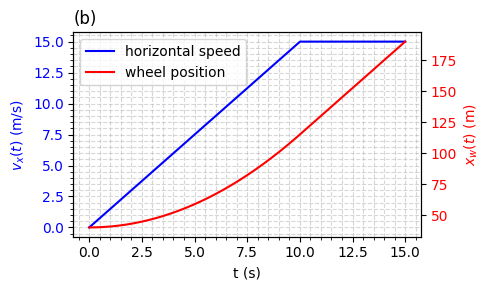

In [12]:
fig, ax1 = plt.subplots(figsize=(5, 3))

color_v = "blue"
color_x = "red"

ax1.plot(cinematica.t, cinematica.v, color=color_v, label="horizontal speed")
ax1.set_xlabel("t (s)")
ax1.set_ylabel("$v_x(t)$ (m/s)", color=color_v)
ax1.tick_params(axis="y", labelcolor=color_v)
ax1.grid(which="both", linestyle="--", alpha=0.5)
ax1.minorticks_on()

ax2 = ax1.twinx()
ax2.plot(cinematica.t, cinematica.x, color=color_x, label="wheel position")
ax2.set_ylabel("$x_w(t)$ (m)", color=color_x)
ax2.tick_params(axis="y", labelcolor=color_x)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("(b)", loc="left")
plt.tight_layout()
plt.savefig("kinematics.png", dpi=300)
plt.show()

Gráfico de la malla

C:\Users\joses\AppData\Local\Temp\ipykernel_22088\794863254.py:105: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


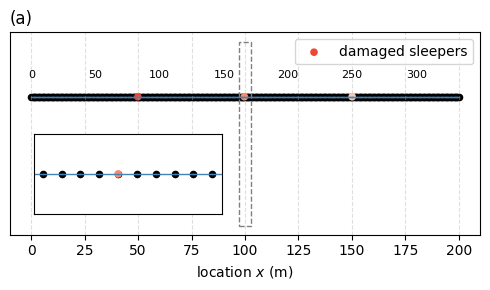

In [13]:
# Gráfico de la malla
fig, ax = plt.subplots(1, 1, figsize=(5, 3), constrained_layout=True)
fig.set_constrained_layout(False)

# -----------------------------
# Dibujar nodos
# -----------------------------
ax.scatter(
    malla.coord_nodos[:, 0],
    np.zeros(malla.n_tot) + .02,
    color="black",
    s=20
)

# -----------------------------
# Resaltar nodos dañados
# -----------------------------
if dano_nodal is not None:
    nodos_danados = list(dano_nodal.keys())
    factores = list(dano_nodal.values())

    x_d = malla.coord_nodos[nodos_danados, 0]

    # Color proportional to damage
    color_damage = plt.cm.Reds(1 - np.array(factores))  # más daño → color más rojo

    ax.scatter(
        x_d,
        np.zeros(len(x_d)) + .02,
        color=color_damage,
        s=20,
        edgecolors=color_damage,
        label="damaged sleepers"
    )

# -----------------------------
# Dibujar elementos (TODOS sanos)
# -----------------------------
for ni, nj in malla.conect:
    x = [malla.coord_nodos[ni, 0], malla.coord_nodos[nj, 0]]
    y = [0.02, 0.02]
    ax.plot(x, y, color="steelblue", lw=1)

# -----------------------------
# Numerar nodos
# -----------------------------
skip_numbers = 50
for i, x in enumerate(malla.coord_nodos[:, 0]):
    if i % skip_numbers == 0:
        ax.text(x, 0.03, str(i), ha="center", fontsize=8)

ax.set_title("(a)", loc='left')
ax.set_xlabel("location $x$ (m)")
ax.set_yticks([])
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right")


# -----------------------------
# Inset (zoom) - versión robusta
# -----------------------------
axins = ax.inset_axes([0.05, 0.1, 0.4, 0.4])  # [x0, y0, width, height] en coords relativas

# rail elements
for ni, nj in malla.conect:
    x = [malla.coord_nodos[ni, 0], malla.coord_nodos[nj, 0]]
    axins.plot(x, [0, 0], color="steelblue", lw=1)

axins.scatter(
    malla.coord_nodos[:, 0],
    np.zeros(malla.n_tot),
    color="black",
    s=20
)

# Zoom
xmin, xmax = 97, 103
axins.set_xlim(xmin, xmax)
axins.set_ylim(-0.05, 0.05)

axins.set_xticks([])
axins.set_yticks([])

if dano_nodal is not None:
    axins.scatter(
        x_d,
        np.zeros(len(x_d)),
        color=color_damage,
        s=20,
        edgecolors=color_damage
    )

# Dibujar rectángulo de zoom en el gráfico principal (manual)
rect = plt.Rectangle(
    (xmin, -0.05),
    xmax - xmin,
    0.1,
    linewidth=1,
    edgecolor="gray",
    linestyle="--",
    facecolor="none"
)
ax.add_patch(rect)

plt.tight_layout()
plt.savefig("mesh_damage.png", dpi=300)
plt.show()

Integración de la ecuación diferencial

In [14]:
load_or_calculate = 'load'

filename_sol = 'sol.pkl'
if load_or_calculate == 'calculate':
    start_time = time.time()
    print(f'{t_sim=}')
    sistema = SistemaViaVehiculo(
    via=via,
    tren=carga,
    sim=sim,
    cinem=cinematica,
    m_inv=m_inv
)
    sol = solve_ivp(
        sistema.rhs,
        (t_eval[0], t_eval[-1]),
        y0,
        t_eval=t_eval,
        method="Radau"
)

    end_time = time.time()
    tiempo_transcurrido = end_time - start_time
    print(f'Tiempo transcurrido: {tiempo_transcurrido} seg = {tiempo_transcurrido / 60} minutos')
    output = {
        "sol": sol,
        "sim": sim,
        "carga": carga,
        "via": via,
        "cinematica": cinematica
    }

    with open(filename_sol, 'wb') as file:
        pickle.dump(output, file)

elif load_or_calculate == 'load':
    with open(filename_sol, 'rb') as file:
        output = pickle.load(file)
    print(f'Solución cargada desde archivo: {filename_sol}')
    sol = output["sol"]
    sim = output["sim"]
    carga = output["carga"]
    via = output["via"]
    cinematica = output["cinematica"]

FileNotFoundError: [Errno 2] No such file or directory: 'sol.pkl'

In [ ]:
sistema = SistemaViaVehiculo(
    via=via,
    tren=carga,
    sim=sim,
    cinem=cinematica,
    m_inv=m_inv
)

Post proceso: Cálculo de aceleraciones

In [ ]:
def calcular_aceleraciones(sol, sistema):
    """
    Reconstruye aceleraciones a partir de la ecuación del movimiento:
        qdd = M^{-1} (F - C qd - K q)

    Parameters
    ----------
    sol : OdeResult
        Resultado de solve_ivp
    sistema : SistemaViaVehiculo
        Sistema que contiene via, carga, cinematica y m_inv

    Returns
    -------
    a : ndarray (ndof, nt)
        Aceleraciones
    """

    ndof = sistema.ndof
    nt = sol.y.shape[1]

    q  = sol.y[0:ndof, :]
    qd = sol.y[ndof:2*ndof, :]

    a = np.zeros((ndof, nt))

    for i, t in enumerate(sol.t):

        # -------------------------
        # Cinemática de la carga
        # -------------------------
        x_c = sistema.cinem.x_fun(t)

        # -------------------------
        # Ensamble instantáneo
        # -------------------------
        F, K, C = sistema.tren.evaluar(x_c)

        # -------------------------
        # Aceleración
        # -------------------------
        a[:, i] = sistema.m_inv @ (F - C @ qd[:, i] - K @ q[:, i])

    return a

Creación de DataFrames

In [ ]:
sol_t = sol.t
sol_y = sol.y

n_q = sol.y.shape[0] // 2
q  = sol.y[:n_q, :]  # Posiciones [u, w, phi]
dq = sol.y[n_q:, :] # Velocidades [du_dt, dw_dt, dphi_dt]

# Indices:
idx_tren = np.arange(0, carga.gdl_ejes + 1)
idx_via = np.arange(carga.gdl_ejes + 1, q.shape[0], dof_malla)
idx_w = np.concatenate([idx_tren, idx_via])

w_tren = q[idx_tren, :] 
w_via = q[idx_via, :]

dw_tren = dq[idx_tren, :]
dw_via = dq[idx_via, :]

n_w_tren = w_tren.shape[0]
n_w_via = w_via.shape[0]

# Definición de los DataFrames de desplazamientos y velocidades
df_w_tren  = pd.DataFrame(w_tren.T,  index=sol_t, columns=[f"w_tren{i}"  for i in range(n_w_tren)])
df_w_via  = pd.DataFrame(w_via.T,  index=sol_t, columns=[f"w_via{i}"  for i in range(n_w_via)])
df_dw_tren  = pd.DataFrame(dw_tren.T,  index=sol_t, columns=[f"dw_tren{i}"  for i in range(n_w_tren)])
df_dw_via  = pd.DataFrame(dw_via.T,  index=sol_t, columns=[f"dw_via{i}"  for i in range(n_w_via)])


# aceleraciones
acel = calcular_aceleraciones(sol, sistema)

ddw_tren = acel[idx_tren, :]
ddw_via = acel[idx_via, :]

# DataFrame
df_ddw_tren = pd.DataFrame(ddw_tren.T, index=sol_t, columns=[f"ddw_tren{i}" for i in range(n_w_tren)])
df_ddw_via  = pd.DataFrame(ddw_via.T,  index=sol_t, columns=[f"ddw_via{i}"  for i in range(n_w_via)])

NameError: name 'sol' is not defined

Gráficos desplazamientos vía-aceleración vagón, ambos en función del tiempo

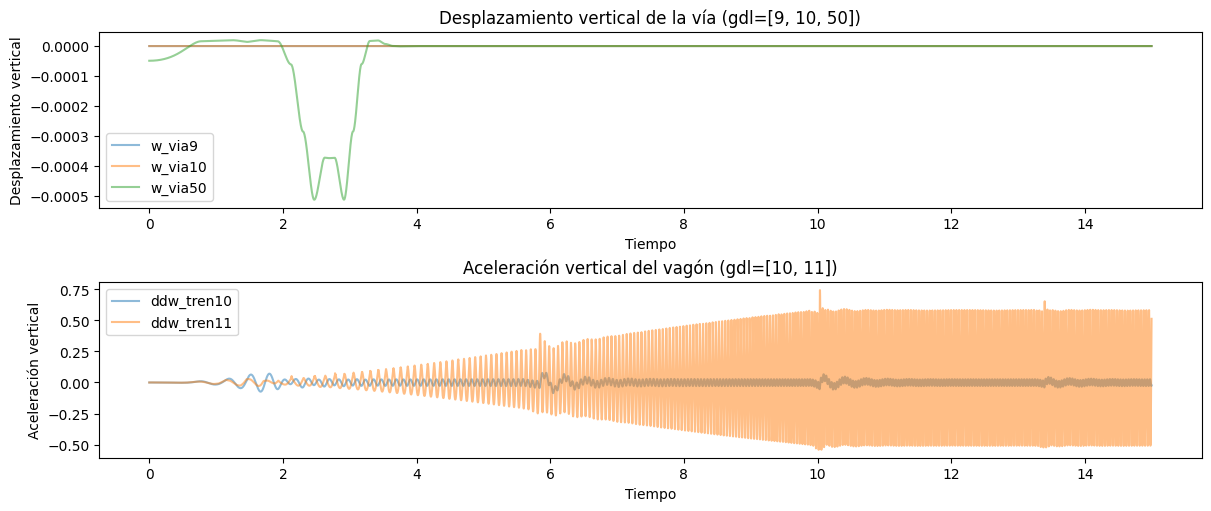

In [ ]:
nodos_via = [9, 10, 50]

desp_via = pd.concat([df_w_tren.iloc[:, [0, 1, 2]], df_w_via.iloc[:, nodos_via]], axis=1) # Para ver desplazamientos de la vía y las masas del tren
desp_via = df_w_via.iloc[:, nodos_via]  # Para ver solo desplazamientos de la vía


fig, axs = plt.subplots(2, 1, figsize=(12, 5), constrained_layout=True)

desp_via.plot(ax=axs[0], alpha=0.5)
axs[0].set_xlabel("Tiempo")
axs[0].set_ylabel("Desplazamiento vertical")
axs[0].set_title(f"Desplazamiento vertical de la vía (gdl={nodos_via})")

# Segundo subplot → aceleraciones
gdl_acel_vagon = [10, 11]
acel_cols = df_ddw_tren.iloc[:, gdl_acel_vagon]
acel_cols.plot(ax=axs[1], alpha=0.5)
axs[1].set_xlabel("Tiempo")
axs[1].set_ylabel("Aceleración vertical")
axs[1].set_title(f"Aceleración vertical del vagón (gdl={gdl_acel_vagon})")
# plt.savefig("grafico.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
df_ddw_tren

,ddw_tren0,ddw_tren1,ddw_tren2,ddw_tren3,ddw_tren4,ddw_tren5,ddw_tren6,ddw_tren7,ddw_tren8,ddw_tren9,ddw_tren10,ddw_tren11,ddw_tren12
0.000,0.000000e+00,-2.910383e-14,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.0
0.001,-1.057101e-07,2.078177e-05,-3.560275e-08,0.000031,-1.837127e-07,0.000030,-3.476248e-08,0.000049,-1.623498e-07,0.000011,3.127701e-08,0.000035,0.0
0.002,-8.545591e-09,4.092954e-05,1.976359e-07,0.000060,-6.890481e-08,0.000059,3.497087e-07,0.000095,-1.888445e-07,0.000022,3.479145e-07,0.000068,0.0
0.003,2.902236e-07,6.043801e-05,6.952401e-07,0.000088,3.430181e-07,0.000087,1.145623e-06,0.000138,-7.825923e-08,0.000034,9.430199e-07,0.000098,0.0
0.004,7.893275e-07,7.930207e-05,1.452734e-06,0.000114,1.050651e-06,0.000114,2.345189e-06,0.000179,1.706306e-07,0.000045,1.809701e-06,0.000126,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
14.995,5.057346e-03,-4.315038e-01,1.033433e-02,-0.507156,-1.488050e-02,-0.176979,-1.314406e-02,-0.286945,-2.253993e-02,0.311126,-2.722008e-02,0.174019,0.0
14.996,1.561286e-03,-4.121086e-01,6.523264e-03,-0.494450,-1.756635e-02,-0.103500,-1.672291e-02,-0.218464,-2.160002e-02,0.371633,-2.773337e-02,0.258238,0.0
14.997,-2.015924e-03,-3.813382e-01,2.531515e-03,-0.471264,-1.980361e-02,-0.025170,-1.994687e-02,-0.142251,-2.031162e-02,0.361848,-2.730413e-02,0.398146,0.0
14.998,-5.582266e-03,-3.405864e-01,-1.554689e-03,-0.437315,-2.151543e-02,0.056488,-2.271856e-02,-0.064316,-1.875606e-02,0.388752,-2.583651e-02,0.486110,0.0


Solo desplazamientos

Text(0.5, 1.0, 'Desplazamiento vertical del vagón (gdl=[0, 1])')

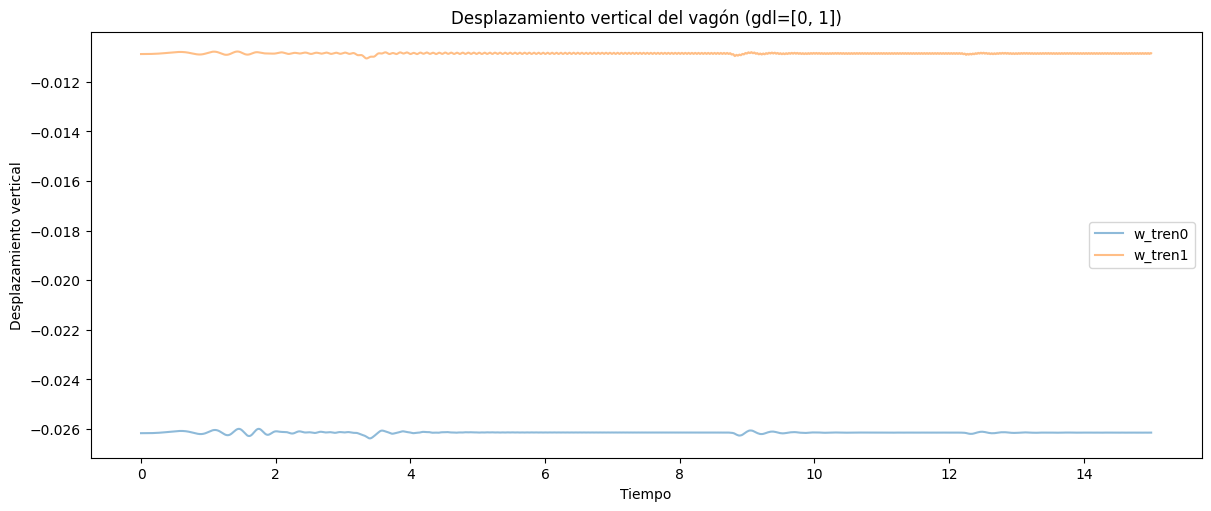

In [ ]:
gdl = [0, 1]


desp = df_w_tren.iloc[:, gdl]

fig, axs = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)

desp.plot(ax=axs, alpha=0.5)
axs.set_xlabel("Tiempo")
axs.set_ylabel("Desplazamiento vertical")
axs.set_title(f"Desplazamiento vertical del vagón (gdl={gdl})")

Solo aceleraciones

Text(0.5, 1.0, 'Aceleraciones verticales del bogie (gdl=[0, 1])')

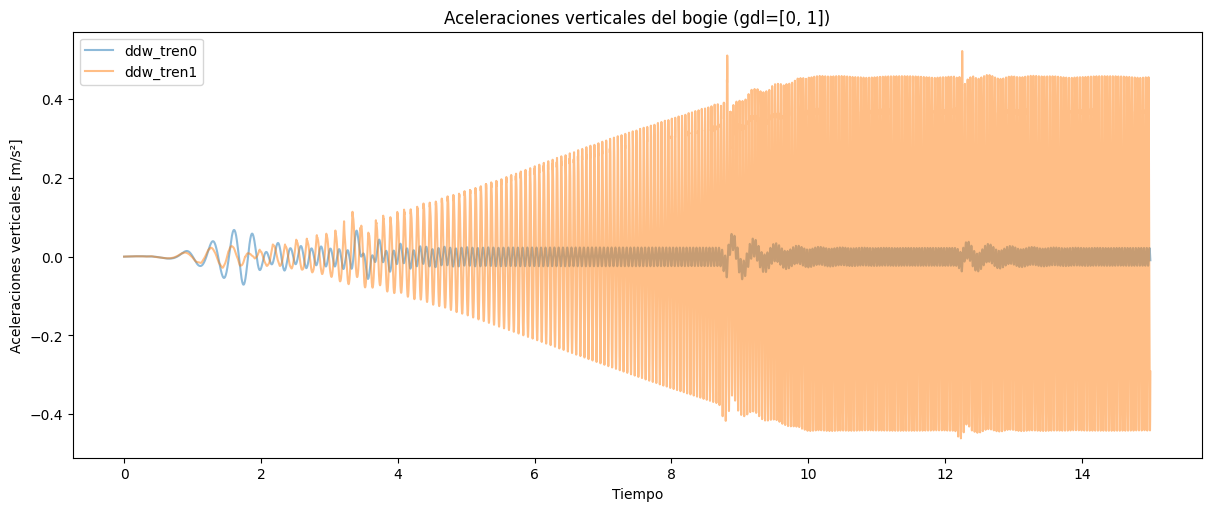

In [ ]:
gdl = [0, 1]


acele = df_ddw_tren.iloc[:, gdl]

fig, axs = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)

acele.plot(ax=axs, alpha=0.5)
axs.set_xlabel("Tiempo")
axs.set_ylabel("Aceleraciones verticales [m/s²]")
axs.set_title(f"Aceleraciones verticales del bogie (gdl={gdl})")

Desplazamientos, velocidades y aceleraciones de la vía

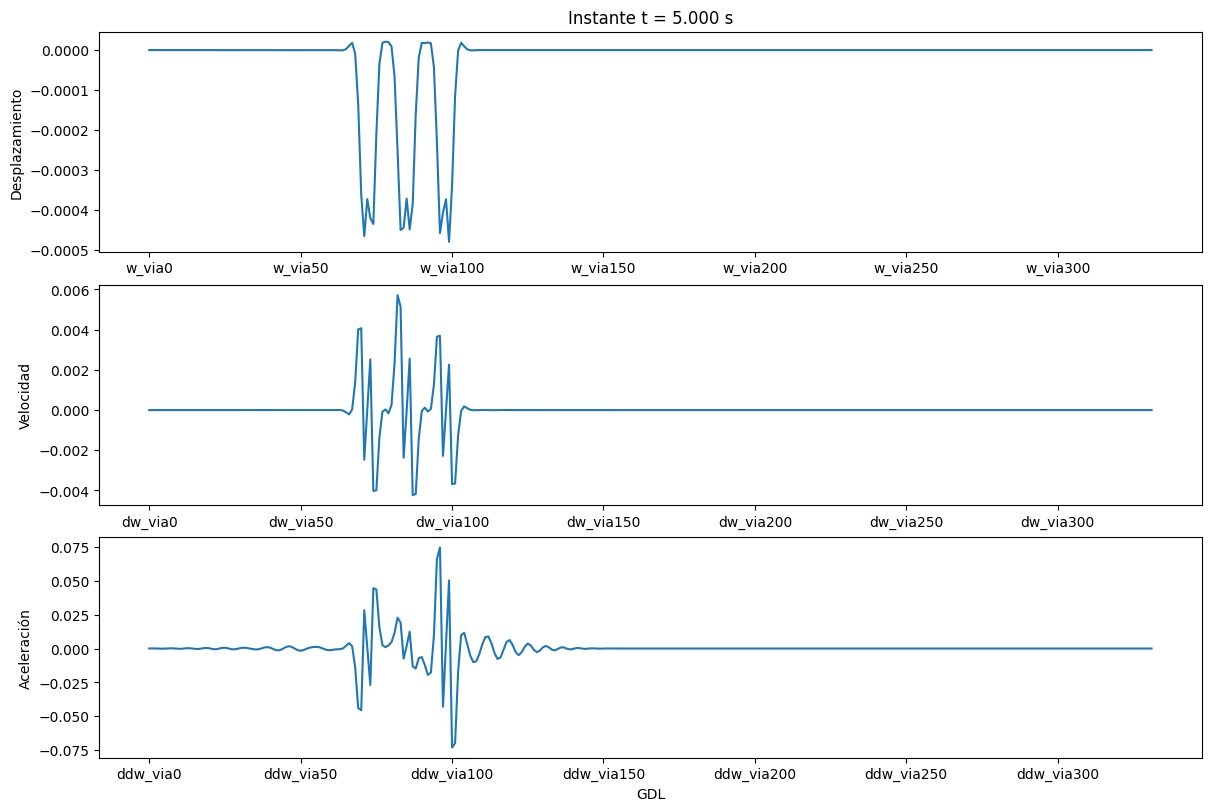

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
i = 5000
w_i = df_w_via.iloc[i]
w_i.plot(ax=axs[0])
axs[0].set_ylabel("Desplazamiento")
axs[0].set_title(f"Instante t = {sol.t[i]:.3f} s")

dw_i = df_dw_via.iloc[i]
dw_i.plot(ax=axs[1])
axs[1].set_ylabel("Velocidad")

ddw_i = df_ddw_via.iloc[i]
ddw_i.plot(ax=axs[2])
axs[2].set_ylabel("Aceleración")
axs[2].set_xlabel("GDL")

plt.show()


Animación de desplazamientos

In [ ]:
import plotly.graph_objects as go
from ipywidgets import IntSlider, VBox

# --- Ejes de tiempo
tiempos = df_w_tren.index.values
nt = len(tiempos)

dataframe = df_w_via

# --- Selección de GDL espaciales (vía)
cols_via = dataframe.columns[carga.gdl_ejes  + 1 :: dof_malla]

# --- Rango global para el eje Y (evita que "salte")
ymin = dataframe[cols_via].min().min()
ymax = dataframe[cols_via].max().max()

# --- Estado inicial (t = t0)
subset0 = dataframe.iloc[0][cols_via]

fig = go.FigureWidget(
    data=[
        go.Scatter(
            x=subset0.index,   # nodos / GDL espaciales
            y=subset0.values,
            mode="markers+lines"
        )
    ],
    layout=go.Layout(
        title=f"Instante t = {tiempos[0]:.3f} s",
        xaxis_title="GDL / Nodo",
        yaxis_title="w",
        yaxis=dict(range=[ymin, ymax])
    )
)

# --- Slider de tiempo
slider = IntSlider(
    min=0,
    max=nt - 1,
    step=1,
    value=0,
    description="t index"
)

def on_change(change):
    idx = change["new"]
    subset = dataframe.iloc[idx][cols_via]

    with fig.batch_update():
        fig.data[0].x = subset.index
        fig.data[0].y = subset.values
        fig.layout.title = f"Instante t = {tiempos[idx]:.3f} s"

slider.observe(on_change, names="value")

VBox([slider, fig])

    'data': [{'mode': 'mar…

# Postprocess Hernán Garrido

Virtual geometric profile

In [ ]:
gdl_tren = tren_params['n_ejes']*2

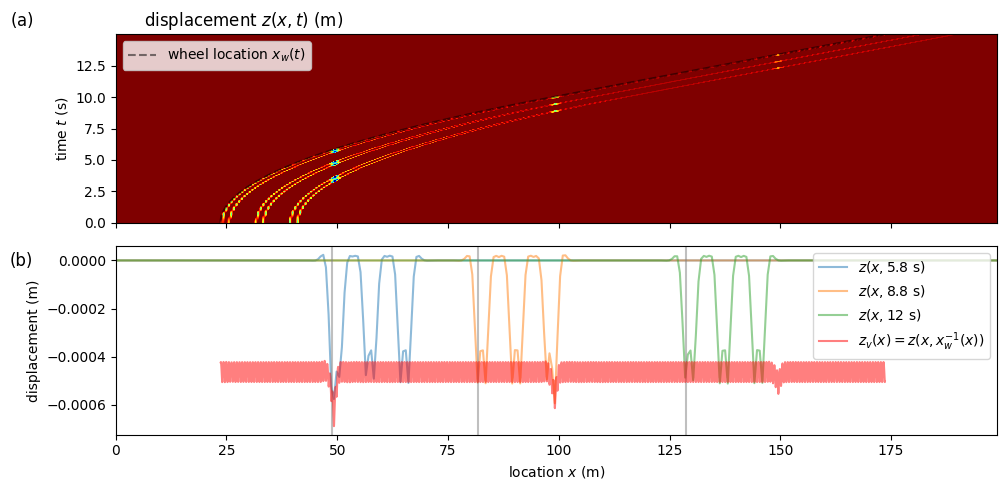

In [ ]:
import numpy as np
import re
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# -------------------------------------------------
# User parameters
# -------------------------------------------------
instants_example = [5.8, 8.8, 12]

t_ini_vgp = 0.01
t_fin_vgp = 14.5

# -------------------------------------------------
# Select time instants inside analysis window
# -------------------------------------------------
instants = df_w_via.index[(df_w_via.index >= t_ini_vgp) & (df_w_via.index <= t_fin_vgp)]

# -------------------------------------------------
# Extract node spatial coordinates
# -------------------------------------------------
coord_nodos = malla.coord_nodos
x_nodes = coord_nodos[:, 0]

# -------------------------------------------------
# Convert column names (e.g., w123) → DOF numbers
# -------------------------------------------------
gdl_via = np.array([int(re.findall(r"\d+", col)[0]) for col in df_w_via.columns])
x_via = x_nodes[gdl_via]

# Assign spatial positions as column labels
df_w_space = df_w_via.copy()
df_w_space.columns = list(x_via)

# Sort columns by spatial position
order = np.argsort(x_via)
df_w_space = df_w_via.iloc[:, order]
x_via = x_via[order]

# -------------------------------------------------
# Extract snapshots
# -------------------------------------------------
fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex='col')
ax_z = axs[0]
ax = axs[1]
# ax_lower = axs[2]

im = ax_z.imshow(
    df_w_space,
    aspect='auto',
    extent=[x_via.min(), x_via.max(), df_w_space.index.min(), df_w_space.index.max()],
    origin='lower',
    cmap='jet',
    vmin=-.0006,
    vmax=-.0004
)
ax_z.set_title('(a)                     displacement $z(x, t)$ (m)', loc='left', x=-0.12)
ax_z.set_ylabel('time $t$ (s)')

# overlap x(t)
ax_z.plot(sistema.cinem.x - 2*carga.d2 - carga.d1/2, sistema.cinem.t, color='black', linestyle='--', 
          label='wheel location $x_w(t)$', alpha=0.5)
ax_z.legend()



snapshots_example = df_w_space.loc[instants_example]
for i, instant in enumerate(instants_example):
    # snapshots_example.iloc[i].plot(ax=ax, label=f"t = {instant} s")
    ax.plot(
        x_via,
        snapshots_example.iloc[i].values,
        label=f"$z(x, {instant}~\mathrm{{s}})$",
        alpha=0.5
    )

snapshots = df_w_space.loc[instants]

# Convert snapshots to NumPy (faster later)
snap_array = snapshots.to_numpy()
time_array = snapshots.index.to_numpy()

# -------------------------------------------------
# Moving contact position x_c(t)
# -------------------------------------------------
t_contact = sistema.cinem.t
x_contact = sistema.cinem.x - 2*carga.d2 - carga.d1/2  # posición del primer eje

# At evenly spaced space points (e.g., every 0.1 m), find the corresponding time instants
# only where velocity is not zero (to avoid extrapolation issues)

x_space = np.arange(x_contact.min(), x_contact.max(), 0.01)
t_space = np.interp(x_space, x_contact, t_contact)

# -------------------------------------------------
# Evaluate displacement at moving contact point
# -------------------------------------------------
w_space = np.zeros_like(t_space)
for i, t in enumerate(t_space):
    # Find the closest time index in df_w_space
    idx_t = np.argmin(np.abs(df_w_space.index - t))
    # Interpolate spatially to find w at the contact point
    w_space[i] = np.interp(x_space[i], x_via, df_w_space.iloc[idx_t].values)

# -------------------------------------------------
# Plot moving contact samples
# -------------------------------------------------
# ax.plot(
#     x_space,
#     w_space,
#     color="gray",
#     label="virtual geometric profile",
#     alpha=0.5
# )


# -------------------------------------------------
# Vertical markers only for example instants
# -------------------------------------------------
instants_example = np.asarray(instants_example)

x_example = np.interp(instants_example, t_contact, x_contact)

for x_t in x_example:
    ax.axvline(x_t, color="gray", linestyle="-", alpha=0.5)


# filter with a moving average where the window_space = 0.1 m
window_space = 0.1
dx = np.diff(x_space)
window_length = int(window_space / np.mean(dx))  # window length in number of points

if window_length > 1:
    w_space_filt = np.convolve(w_space, np.ones(window_length)/window_length, mode='valid')
    x_space_filt = x_space[window_length//2:-window_length//2 + 1]
else:
    print("Warning: Skipping filtering.")
    w_space_filt = w_space
    x_space_filt = x_space

ax.plot(
    x_space_filt,
    w_space_filt,
    color="red",
    label="$z_v(x)=z(x, x_w^{-1}(x))$",
    alpha=0.5
)
ax.set_ylabel("displacement (m)")
ax.legend(loc="upper right")
ax.set_title('(b)', loc='left', y=0.85, x=-0.12)

# -------------------------------------------------
# Curvature (second derivative) of virtual geometric profile
# -------------------------------------------------
w_space_d = np.diff(w_space_filt)/np.diff(x_space_filt)
w_space_dd = np.diff(w_space_d)/np.diff(x_space_filt[1:])


# skip = 3
# ax_lower.plot(
#     x_space_filt[skip:-skip],
#     w_space_dd[skip-2:-skip],
#     color="black",
#     label="curvature of virtual geometric profile $z_v''(x)$",
# )

# ax_lower.legend(loc="lower left")
# ax_lower.set_ylabel(r"Curvature (m/m$^2$)")
# ax_lower.set_xlabel("location x (m)")


ax.set_xlabel("location $x$ (m)")

# ax_lower.set_ylim(-.001, .001)

plt.tight_layout()
plt.savefig("virtual_geometric_profile.png", dpi=300, bbox_inches='tight')
plt.show()


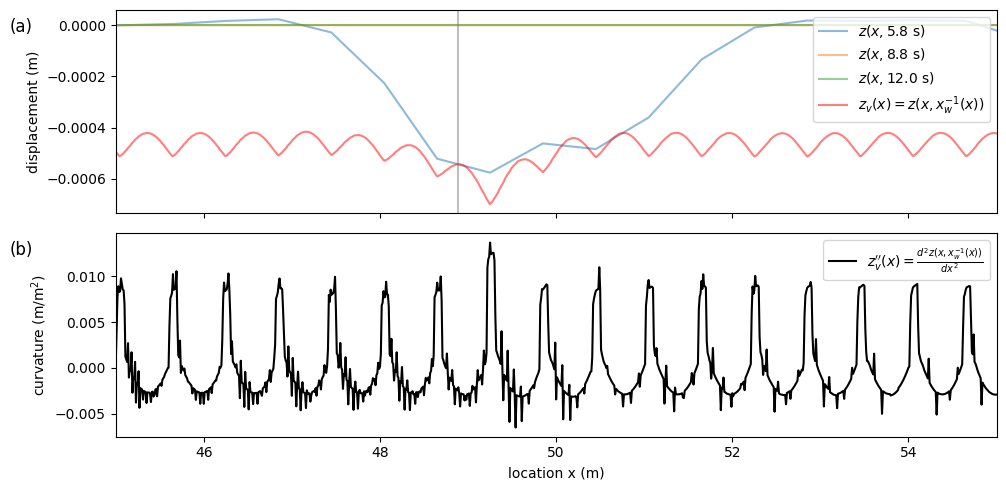

In [ ]:

# -------------------------------------------------
# Extract snapshots
# -------------------------------------------------
fig, axs = plt.subplots(2,1, figsize=(10, 5), sharex='col')
ax = axs[0]
ax_lower = axs[1]

for i, instant in enumerate(instants_example):
    # snapshots_example.iloc[i].plot(ax=ax, label=f"t = {instant} s")
    ax.plot(
        x_via,
        snapshots_example.iloc[i].values,
        label=f"$z(x, {instant}~\mathrm{{s}})$",
        alpha=0.5
    )

# -------------------------------------------------
# Plot moving contact samples
# -------------------------------------------------
ax.plot(
    x_space,
    w_space,
    color="red",
    label="$z_v(x) = z(x, x_w^{-1}(x))$",
    alpha=0.5
)


# -------------------------------------------------
# Vertical markers only for example instants
# -------------------------------------------------
for x_t in x_example:
    ax.axvline(x_t, color="gray", linestyle="-", alpha=0.5)

# ax.plot(
#     x_space_filt,
#     w_space_filt,
#     color="gray",
#     label="virtual geometric profile (filtered)",
#     alpha=0.5
# )
ax.set_ylabel("displacement (m)")

# the title is usad to put (a), so it has to e positioned under the title typical line and to the left
ax.set_title("(a)", loc="left", y=0.85, x=-0.12)
ax.legend(loc="upper right")


# -------------------------------------------------
# Curvature (second derivative) of virtual geometric profile
# -------------------------------------------------
skip = 2
ax_lower.plot(
    x_space_filt[skip:-skip],
    w_space_dd[skip-2:-skip],
    color="black",
    label=r"$z_v''(x) = \frac{d^2 z(x, x_w^{-1}(x))}{d x^2}$"
)

ax_lower.legend(loc="upper right")
ax_lower.set_ylabel(r"curvature (m/m$^2$)")
ax_lower.set_xlabel("location x (m)")
ax_lower.set_title("(b)", loc="left", y=0.85, x=-0.12)

# ax_lower.set_xlim(95, 105)
ax_lower.set_xlim(45, 55)

plt.tight_layout()
plt.savefig("curvature_zoom.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np
from scipy.signal import spectrogram
from scipy.interpolate import interp1d


def spatial_spectrogram_lambda(
    x,
    signal,
    window_length,
    overlap=0.5,
    nfft=None,
    match_original_x=True
):

    # -------------------------------------------------
    # 1) Interpolate to uniform spatial grid
    # -------------------------------------------------
    dx = np.median(np.diff(x))

    x_uniform = np.arange(x[0], x[-1] + dx, dx)

    interp_fun = interp1d(x, signal, kind="linear", fill_value="extrapolate")
    sig_uniform = interp_fun(x_uniform)

    # -------------------------------------------------
    # 2) Window parameters
    # -------------------------------------------------
    nperseg = max(2, int(round(window_length / dx)))

    if nfft is None:
        nfft = max(256, 2 ** int(np.ceil(np.log2(nperseg))))

    noverlap = int(overlap * nperseg)

    # -------------------------------------------------
    # 3) Spectrogram
    # -------------------------------------------------
    f_spatial, t_spec, S = spectrogram(
        sig_uniform,
        fs=1 / dx,          # spatial sampling frequency
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        scaling="spectrum",
        mode="psd"
    )

    # # Remove DC
    # f_spatial = f_spatial[1:]
    # S = S[1:, :]

    lambda_vals = 1 / (f_spatial + 1e-6)

    # -------------------------------------------------
    # 4) TRUE spatial locations of STFT slices
    # -------------------------------------------------
    x_centers = x_uniform[0] + t_spec

    # -------------------------------------------------
    # 5) Optional interpolation to original x grid
    # -------------------------------------------------
    if match_original_x:

        S_interp = np.empty((len(lambda_vals), len(x)))

        for i in range(len(lambda_vals)):

            interp_S = interp1d(
                x_centers,
                S[i],
                bounds_error=False,
                fill_value=np.nan
            )

            S_interp[i] = interp_S(x)

        return lambda_vals, x, S_interp

    return lambda_vals, x_centers, S


In [ ]:
def plot_spectrogram(
    spectrogram_,
    ax=None,
    fig=None,
    tlim=None,
    flim=None,
    title=None,
    spatial=False,
    x_index=False,
    v_min_max=None,
    period=False,
    log_scale=False,
):
    if log_scale:
        f, t, Sxx = spectrogram_[0], spectrogram_[1], np.log(spectrogram_[2])
    else:
        f, t, Sxx = spectrogram_[0], spectrogram_[1], spectrogram_[2]
    if x_index:
        t = np.arange(len(t))
    if ax is None:
        fig, ax = plt.subplots(figsize=(20, 5))
    if v_min_max:
        im = ax.pcolormesh(
            t, f, Sxx, shading=None, cmap="jet", vmin=v_min_max[0], vmax=v_min_max[1]
        )
    else:
        im = ax.pcolormesh(t, f, Sxx, shading=None, cmap="jet")
    ax.set_ylabel(
        ("frequency (Hz)" if not spatial else "spatial frequency (1/m)")
        if not period
        else ("period (s)" if not spatial else "wavelength $\lambda$ (m)")
    )
    ax.set_xlabel("Time (s)" if not x_index else "Sample index")
    fig.colorbar(im, ax=ax)
    if tlim is not None:
        ax.set_xlim(tlim)
    if flim is not None:
        ax.set_ylim(flim)
    if title:
        ax.set_title(title)

    return ax


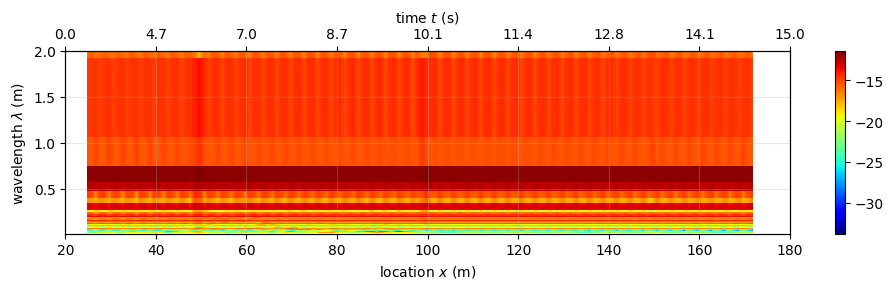

In [ ]:
# --- Compute spectrogram ---
lambda_vals, x_spec, S_lambda = spatial_spectrogram_lambda(
    x_space_filt[skip:-skip], w_space_dd[skip - 2 : -skip], window_length=2
)

# -------------------------------------------------
# Pack spectrogram in expected format
# -------------------------------------------------
spectrogram_space = (lambda_vals, x_spec, S_lambda)

# -------------------------------------------------
# Plot using helper
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3))

plot_spectrogram(
    spectrogram_space,
    ax=ax,
    fig=fig,
    flim=(0.01, 2),
    # title="Spatial spectrogram of curvature",
    spatial=True,
    period=True,
    log_scale=True,
)


# Override x label (helper assumes time)
ax.set_xlabel(r"location $x$ (m)")
ax.grid(True, alpha=0.3)

# add another horizontal scale in terms of time using cinematica.t, cinematica.x
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
x_ticks = ax2.get_xticks()
t_ticks = np.interp(
    x_ticks, sistema.cinem.x - 2 * carga.d2 - carga.d1 / 2, sistema.cinem.t
)
ax2.set_xticks(x_ticks)
ax2.set_xticklabels([f"{t:.1f}" for t in t_ticks])
ax2.set_xlabel("time $t$ (s)")

# update xticks of ax
ax.set_xlim(x_ticks[0], x_ticks[-1])

plt.tight_layout()
plt.savefig("actual_curvature_spectrogram.png", dpi=300, bbox_inches="tight")
plt.show()


## Export as it was smartphone mesurements

NameError: name 'acel_cols' is not defined

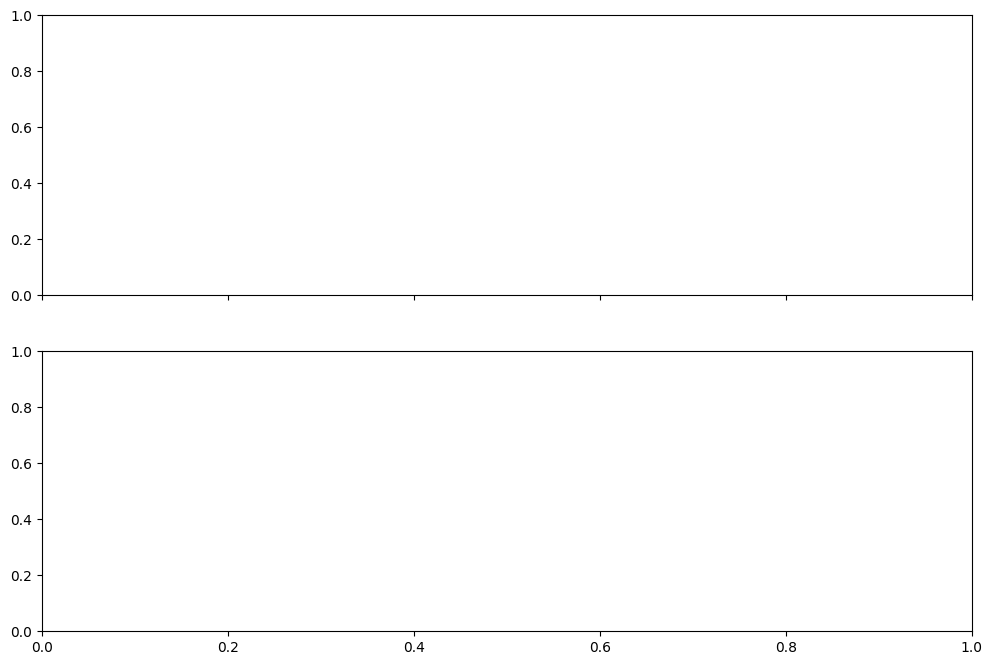

In [ ]:
# Delta_t statistics
# print(pd.DataFrame(np.diff(acel_cols.index, 1)).describe())
fig, ax = plt.subplots(2,1, figsize=(12, 8), sharex='col')
# ax.set_xlim([2.0, 3.5])

# Actual data
ax[1].plot(acel_cols.index, acel_cols.values[:, 0], label='actual value')

# subsampling at 100 sps
t_100sps = np.arange(0, acel_cols.index[-1], .01)
acel_cols_100sps = pd.Series(index=t_100sps,
                             data=np.interp(t_100sps, acel_cols.index, acel_cols.values[:, 0]))
ax[1].plot(t_100sps, acel_cols_100sps, marker='o', linestyle='none', label='sensor')

ax[1].legend()

with open('acel_cols_100sps.pkl', 'wb') as file:
    pickle.dump(acel_cols_100sps, file)

acel_cols_100sps.to_csv('Accelerometer.csv')
with open('Accelerometer.csv', 'r') as file:
    lines = file.readlines()

lines[0] = "seconds_elapsed,z\n"

with open('Accelerometer.csv', 'w') as file:
    file.writelines(lines)


# simulate lat lon
# t_1sps = np.arange(0, acel_cols.index[-1] + 1, 1.0)
t_1sps = np.arange(0, acel_cols.index[-1], 1.0)
data = {
    'seconds_elapsed': t_1sps,
    'speed': np.interp(t_1sps, cinematica.t, cinematica.v),
    'latitude': np.interp(t_1sps, cinematica.t, cinematica.x),
    'longitude': np.zeros(len(t_1sps))
}
location_1sps = pd.DataFrame(data=data)
location_1sps.to_csv('Location.csv')

# Actual speed
# ax[0].plot(cinematica.t, cinematica.v, label='actual speed')

ax[0].plot(data['seconds_elapsed'], data['speed'], linestyle='none', marker='o', label='GPS speed')
ax[0].legend()

# ax.set_xlim(0,1)

In [ ]:
cinematica.t.shape

(15000,)

Analytical FRF

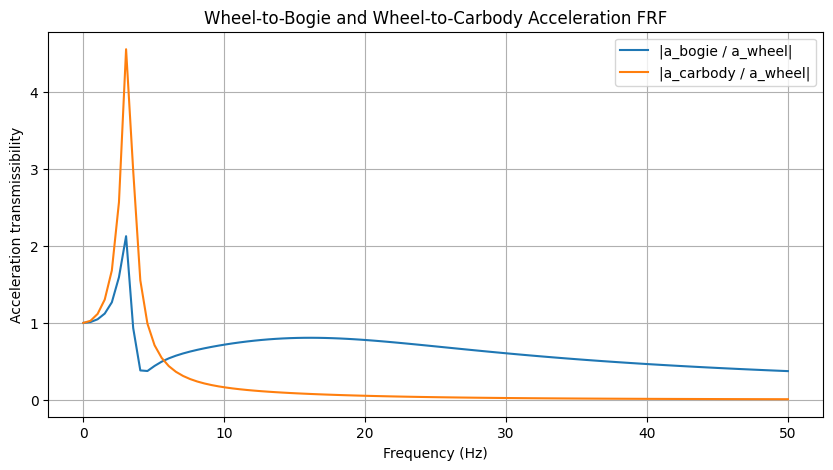

In [15]:
def analytical_acceleration_frf(m1, m2, k1, k2, c1, c2):
    """Return wheel-acceleration-to-body-acceleration transfer functions.

    The DOF order follows CargaMovil: quarter-carbody (m1), then bogie (m2).
    The wheel/rail acceleration is the base input through the primary
    suspension (k2, c2). The returned vector is ordered [carbody, bogie].
    """
    M = np.diag([m1, m2])
    K = np.array([
        [k1, -k1],
        [-k1, k1 + k2]
    ])
    C = np.array([
        [c1, -c1],
        [-c1, c1 + c2]
    ])

    def frf(omega):
        dynamic_stiffness = K - omega**2 * M + 1j * omega * C
        wheel_base_input = np.array([0.0, k2 + 1j * omega * c2])
        # Acceleration and displacement transmissibilities are equal for harmonic motion.
        return np.linalg.solve(dynamic_stiffness, wheel_base_input)

    return frf


# Plot from 0 to 50 Hz
f_range = np.linspace(0, 50, 100)
omega_range = 2 * np.pi * f_range

acceleration_frf = analytical_acceleration_frf(
    tren.m1, tren.m2, tren.k1, tren.k2, tren.c1, tren.c2
)
acceleration_transfer = np.array([acceleration_frf(omega) for omega in omega_range])

# Transfer ratios: output acceleration / wheel (rail-contact) acceleration
H_carbody = acceleration_transfer[:, 0]
H_bogie = acceleration_transfer[:, 1]

plt.figure(figsize=(10, 5))
plt.plot(f_range, np.abs(H_bogie), label='|a_bogie / a_wheel|')
plt.plot(f_range, np.abs(H_carbody), label='|a_carbody / a_wheel|')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Acceleration transmissibility')
plt.title('Wheel-to-Bogie and Wheel-to-Carbody Acceleration FRF')
plt.legend()
plt.grid(True)
plt.show()

# save the FRF data to CSV
frf_data = pd.DataFrame({
    'Frequency (Hz)': f_range,
    'Bogie Acceleration Transmissibility': np.abs(H_bogie),
    'Carbody Acceleration Transmissibility': np.abs(H_carbody)
})
frf_data.to_csv('acceleration_frf.csv', index=False)